# Chapter 64: Institutions, State Formation, and Long-Run Development

This notebook reruns four worked examples from the chapter: a merchant boycott that disciplines a ruler, taxes that carry war debt, a growth gap that reverses an income lead, and catch-up from far behind. Every number is one of the chapter's constructed teaching numbers, not historical data; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def repeated_deterrence(flow, cost, delta, grab, m):
    """Ruler's cooperate value V_H = (flow - cost)/(1 - delta), deviation value V_P(m) = grab + (1 - m) V_H,
    and the threshold withdrawal share m* = grab / V_H; returns a dict.

    merchant-guild-commitment-mechanism (chapter 64): V_H = (24 - 6)/(1 - 0.75) = 72,
    V_P(0.25) = 55 + 72(0.75) = 109, m* = 55/72 = 0.764.
    """
    v_h = (flow - cost) / (1.0 - delta)
    v_p = grab + (1.0 - m) * v_h
    return {"V_H": v_h, "V_P": v_p, "m_star": grab / v_h, "deterred": v_p <= v_h}


def exp_path(y0, g, T, discrete=False):
    """Level after T periods at growth g: y0 e^(g T), or y0 (1 + g)^T when discrete is True.

    ak-endogenous-growth-mechanism (chapter 61): 50 e^(0.02 x 10) = 61.07 and
    50 e^(0.035 x 10) = 70.95.
    """
    return y0 * (1.0 + g) ** T if discrete else y0 * math.exp(g * T)


def catch_up(A0, frontier, theta):
    """One-period catch-up: A1 = A0 + theta (frontier - A0); returns {"A1", "growth"}.

    advantage-of-backwardness (chapter 64): 35 + 0.25(100 - 35) = 51.25, growth 46.43 percent;
    75 + 0.25(100 - 75) = 81.25, growth 8.33 percent.
    """
    A1 = A0 + theta * (frontier - A0)
    return {"A1": A1, "growth": A1 / A0 - 1.0}


def debt_path(B0, r, deficit, seigniorage):
    """Real debt B_t = (1 + r) B_{t-1} + D - S_t for each seigniorage entry; returns [B0, B1, ...].

    unpleasant-monetarist-arithmetic (chapter 54): 100, r 0.10, D 5, S (10, 10) gives 105, 110.5;
    S1 = 0 gives 115.
    """
    path = [B0]
    for s in seigniorage:
        path.append((1 + r) * path[-1] + deficit - s)
    return path


def annuity_factor(r, n):
    """Present value of 1 per period for n periods: (1 - (1 + r)^-n) / r (n when r = 0)."""
    return float(n) if r == 0 else (1.0 - (1.0 + r) ** (-n)) / r


def annuity_pv(payment, r, n):
    """payment x annuity_factor(r, n)."""
    return payment * annuity_factor(r, n)


plt.rcParams.update(HOUSE_RC)


games = SimpleNamespace(repeated_deterrence=repeated_deterrence)


growth = SimpleNamespace(exp_path=exp_path, catch_up=catch_up)


macro = SimpleNamespace(debt_path=debt_path)


choice = SimpleNamespace(annuity_factor=annuity_factor, annuity_pv=annuity_pv)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'merchant-guild-commitment-mechanism': {'T': 24,
                                         'c': 6,
                                         'delta': 0.75,
                                         'P': 55,
                                         'V_H': 72,
                                         'm_star': 0.764,
                                         'V_P_025': 109,
                                         'merchant_gain': 9,
                                         'merchant_margin': 3,
                                         'merchant_loss': 12},
 'fiscal-military-state': {'D': 240,
                           'r': 0.05,
                           'G': 60,
                           'M_war': 90,
                           'M_peace': 35,
                           'T_old': 95,
                           'T_new': 120,
                           'D1_no_tax': 307,
                           'borrow_no_tax': 67,
                           'D1': 282,
                           'borrow': 42,
                           'D2': 271.1,
                           'reduction': 10.9,
                           'primary_surplus': 25,
                           'interest': 14.1},
 'reversal-of-fortune': {'P_A': 0.9,
                         'P_B': 0.3,
                         'beta': 0.6,
                         'J_A': 0.46,
                         'J_B': 0.82,
                         'g_A': 0.0195,
                         'g_B': 0.0285,
                         'Y0_A': 150,
                         'Y0_B': 100,
                         'years': 60,
                         'Y_A': 477.89,
                         'Y_B': 539.83,
                         'ratio_printed_as': 0.89,
                         'ratio_exact_4dp': 0.8853},
 'advantage-of-backwardness': {'frontier': 100,
                               'A0': 35,
                               'A0_near': 75,
                               'theta': 0.25,
                               'A1': 51.25,
                               'growth': 0.4643,
                               'A1_near': 81.25,
                               'growth_near': 0.0833,
                               'cost': 72,
                               'private': 45,
                               'gap': 27,
                               'benefit': 20,
                               'n': 5,
                               'r': 0.08,
                               'pv': 79.85,
                               'npv': 7.85},
 'constructed': {'merchant-guild-commitment-mechanism': {'m': [0.5], 'delta': [0.6, 0.9]},
                 'fiscal-military-state': {'T': [145], 'r': [0.03, 0.08]},
                 'reversal-of-fortune': {'beta': [0.3, 0.9], 'years': [20, 40]},
                 'advantage-of-backwardness': {'A0': [55], 'theta': [0.1, 0.4]}}}


LABEL = "Constructed teaching numbers, not historical data."


def guild_picture(m=1.0, delta=0.75):
    b = BV["merchant-guild-commitment-mechanism"]
    r = games.repeated_deterrence(b["T"], b["c"], delta, b["P"], m)
    v_h, v_p, m_star = r["V_H"], r["V_P"], r["m_star"]
    fig, ax = new_figure()
    bar_compare(ax, ["Protect: V_H", "Confiscate: V_P(m)"], [v_h, v_p], colors=["teal", "terracotta"],
                value_labels=[num(v_h), num(v_p)], ylabel="Ruler's value", xlabel="Ruler's choice")
    hline(ax, v_h, col="teal")
    ax.set_ylim(0, max(v_h, v_p) * 1.25)
    if v_p < v_h:
        verdict = "protection pays and the ruler respects property"
    elif v_p > v_h:
        verdict = "confiscation pays and the threat does not discipline the ruler"
    else:
        verdict = "the two values tie, so the ruler is indifferent"
    if m_star > 1:
        need = (f"m* = 55 / {num(v_h)} = {num(m_star, 3)} exceeds 1, so even a complete boycott cannot deter "
                f"this impatient ruler")
    else:
        need = f"Deterrence needs m at least 55 / {num(v_h)} = {num(m_star, 3)}"
    if m_star <= 1 and abs(m - m_star) < 0.001:
        need += (f"; the share {num(m, 3)} is m* rounded to three decimals (exact {num(m_star, 5)}), so it clears "
                 f"the threshold only narrowly")
    lost = (1 - m) * v_h
    metrics = {"Cooperate value V_H": num(v_h), "Confiscate value V_P(m)": num(v_p),
               "Threshold share m*": num(m_star, 3), "Share withdrawn m": num(m, 3),
               "Ruler's choice": "Protect" if v_p < v_h else ("Confiscate" if v_p > v_h else "Indifferent (tie)")}
    steps = [f"V_H = (24 - 6) / (1 - {num(delta)}) = 18 / {num(1 - delta)} = {num(v_h)}",
             f"Commerce kept after confiscation: (1 - {num(m, 3)}) x {num(v_h)} = {num(lost)}",
             f"V_P(m) = 55 + {num(lost)} = {num(v_p)}",
             f"m* = 55 / {num(v_h)} = {num(m_star, 3)}" + (", above 1, so no boycott share can deter" if m_star > 1 else ""),
             f"V_P(m) = {num(v_p)} against V_H = {num(v_h)}: {verdict}"]
    interp = (f"{LABEL} Cooperation is worth (24 - 6) / (1 - {num(delta)}) = {num(v_h)}. Withdrawing {num(m, 3)} of "
              f"commerce leaves the ruler 55 + {num(lost)} = {num(v_p)} from confiscation, so {verdict}. {need}.")
    alt = (f"Two bars: protecting is worth {num(v_h)} and confiscating with {num(m, 3)} of commerce withdrawn is "
           f"worth {num(v_p)}. The threshold share is {num(m_star, 3)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def war_debt_picture(tax=120, r=0.05):
    b = BV["fiscal-military-state"]
    D0, G = b["D"], b["G"]
    d1 = macro.debt_path(D0, r, G + b["M_war"], [tax])[1]
    d2 = macro.debt_path(d1, r, G + b["M_peace"], [tax])[1]
    borrow = d1 - D0
    surplus = tax - G - b["M_peace"]
    interest = r * d1
    change = d1 - d2
    R = 1 + r
    fig, ax = new_figure()
    bar_compare(ax, ["Start D_t", "War year D_t+1", "Peace year D_t+2"], [D0, d1, d2],
                colors=["grey", "terracotta", "teal"], value_labels=[num(D0), num(d1), num(d2)],
                ylabel="Public debt", xlabel="Year")
    ax.set_ylim(0, max(D0, d1, d2) * 1.25)
    if change > 0:
        peace = f"debt falls by {num(change)}"
    elif change < 0:
        peace = f"debt still rises by {num(-change)}"
    else:
        peace = "debt is unchanged"
    metrics = {"War year debt D_t+1": num(d1), "War borrowing": num(borrow), "Peace year debt D_t+2": num(d2),
               "Peace primary surplus": num(surplus), "Peace interest": num(interest),
               "Peace change in debt": num(-change)}
    steps = [f"D_t+1 = {num(R)} x 240 + 60 + 90 - {tax} = {num(R * D0)} + 150 - {tax} = {num(d1)}",
             f"War borrowing = {num(d1)} - 240 = {num(borrow)}",
             f"D_t+2 = {num(R)} x {num(d1)} + 60 + 35 - {tax} = {num(R * d1)} + 95 - {tax} = {num(d2)}",
             f"Primary surplus = {tax} - 60 - 35 = {num(surplus)}; interest = {num(r)} x {num(d1)} = {num(interest)}",
             f"Change in peace = {num(interest)} - {num(surplus)} = {num(-change)}, so {peace}"]
    interp = (f"{LABEL} With taxes of {tax} and interest at {pct(r, 0)}, war-year debt is {num(R)} x 240 + 60 + 90 - {tax} = {num(d1)}, so the state "
              f"borrows {num(borrow)}. In the peace year the primary surplus is {num(surplus)} against interest of "
              f"{num(interest)}, so {peace}.")
    alt = (f"Three debt bars: 240 at the start, {num(d1)} after the war year and {num(d2)} after the peace year, "
           f"with taxes of {tax} and interest at {pct(r, 0)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def reversal_picture(beta=0.60, years=60):
    b = BV["reversal-of-fortune"]
    jA, jB = 1 - beta * b["P_A"], 1 - beta * b["P_B"]
    gA, gB = 0.008 + 0.025 * jA, 0.008 + 0.025 * jB
    yA = growth.exp_path(b["Y0_A"], gA, years, discrete=True)
    yB = growth.exp_path(b["Y0_B"], gB, years, discrete=True)
    ratio = yA / yB
    ts = np.arange(0, years + 1)
    pa = [growth.exp_path(b["Y0_A"], gA, t, discrete=True) for t in ts]
    pb = [growth.exp_path(b["Y0_B"], gB, t, discrete=True) for t in ts]
    fig, (ax1, ax2) = new_figure(ncols=2)
    ax1.plot(ts, pa, color=PALETTE["terracotta"], linewidth=2.2)
    ax1.plot(ts, pb, color=PALETTE["teal"], linewidth=2.2)
    top = max(yA, yB, 150)
    a_high = yA >= yB
    mark(ax1, years, yA, f"A: {num(yA)}", col="terracotta", dx=-8, dy=6 if a_high else -8, ha="right",
         va="bottom" if a_high else "top")
    mark(ax1, years, yB, f"B: {num(yB)}", col="teal", dx=-8, dy=-8 if a_high else 6, ha="right",
         va="top" if a_high else "bottom")
    ax1.set_xlim(0, years * 1.05)
    ax1.set_ylim(0, top * 1.18)
    ax1.set_xlabel("Years")
    ax1.set_ylabel("Income index")
    ax2.plot(ts, np.array(pa) / np.array(pb), color=PALETTE["navy"], linewidth=2.2)
    hline(ax2, 1.0, "equal income", col="grey")
    mark(ax2, years, ratio, f"Y_A / Y_B = {num(ratio, 4)}", col="navy", dx=-8, dy=8, ha="right")
    ax2.set_xlim(0, years * 1.05)
    ax2.set_ylim(0.6, 1.6)
    ax2.set_xlabel("Years")
    ax2.set_ylabel("Income ratio A to B")
    if ratio > 1:
        verdict = f"A is still ahead, {pct(ratio - 1)} richer"
    elif ratio < 1:
        verdict = f"B has overtaken A, which is {pct(1 - ratio)} poorer"
    else:
        verdict = "the two have equal income"
    metrics = {"J_A": num(jA, 3), "J_B": num(jB, 3), "g_A": pct(gA, 3), "g_B": pct(gB, 3),
               "Y_A": num(yA), "Y_B": num(yB), "Ratio Y_A / Y_B": num(ratio, 4)}
    steps = [f"J_A = 1 - {num(beta)} x 0.90 = {num(jA, 3)}; J_B = 1 - {num(beta)} x 0.30 = {num(jB, 3)}",
             f"g_A = 0.008 + 0.025 x {num(jA, 3)} = {num(gA, 5)}; g_B = 0.008 + 0.025 x {num(jB, 3)} = {num(gB, 5)}",
             f"Y_A = 150 x ({num(1 + gA, 5)})^{years} = {num(yA)}",
             f"Y_B = 100 x ({num(1 + gB, 5)})^{years} = {num(yB)}",
             f"Y_A / Y_B = {num(yA)} / {num(yB)} = {num(ratio, 4)}"]
    interp = (f"{LABEL} With slope {num(beta)}, inclusion is {num(jA, 3)} in A and {num(jB, 3)} in B, so A grows "
              f"0.008 + 0.025 x {num(jA, 3)} = {num(gA, 5)} a year and B 0.008 + 0.025 x {num(jB, 3)} = {num(gB, 5)}. After {years} years income is {num(yA)} in A and {num(yB)} in "
              f"B: {verdict}.")
    alt = (f"Left: income paths over {years} years, A from 150 to {num(yA)} and B from 100 to {num(yB)}. Right: the "
           f"ratio of A to B income, ending at {num(ratio, 4)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def backwardness_picture(a0=35, theta=0.25):
    b = BV["advantage-of-backwardness"]
    res = growth.catch_up(a0, b["frontier"], theta)
    a1, g = res["A1"], res["growth"]
    pv = choice.annuity_pv(b["benefit"], b["r"], b["n"])
    npv = pv - b["cost"]
    fig, ax = new_figure()
    xs = np.arange(2)
    ax.bar(xs, [a0, a1], color=[PALETTE["grey"], PALETTE["teal"]], width=0.55)
    ax.set_xticks(xs, ["Before: A_0", "After: A_1"])
    hline(ax, b["frontier"], "frontier A* = 100", col="navy", style="solid")
    label(ax, 0, a0, num(a0), dx=0, dy=4, ha="center", box=False)
    label(ax, 1, a1, f"{num(a1)} (+{pct(g, 2)})", dx=0, dy=4, ha="center", box=False)
    ax.set_ylim(0, 118)
    ax.set_ylabel("Productivity")
    ax.set_xlabel("Period")
    gap = b["frontier"] - a0
    metrics = {"A_1": num(a1), "Growth": pct(g, 2), "Gap closed": num(theta * gap),
               "Package PV": num(pv), "Package NPV": num(npv)}
    steps = [f"Gap = 100 - {num(a0, 0)} = {num(gap, 0)}",
             f"A_1 = {num(a0, 0)} + {num(theta)} x {num(gap, 0)} = {num(a0, 0)} + {num(theta * gap)} = {num(a1)}",
             f"Growth = ({num(a1)} - {num(a0, 0)}) / {num(a0, 0)} = {num(g, 4)}, or {pct(g, 2)}",
             f"PV = 20 x (1 - 1.08^-5) / 0.08 = {num(pv)}; NPV = {num(pv)} - 72 = {num(npv)}"]
    interp = (f"{LABEL} Starting at {num(a0, 0)} with a gap of {num(gap, 0)}, closing {pct(theta, 0)} of it lifts "
              f"productivity to {num(a0, 0)} + {num(theta)} x {num(gap, 0)} = {num(a1)}, growth of {pct(g, 2)}. The larger the starting gap, the faster the "
              f"percentage growth from the same catch-up share. The book's adoption package, a fixed example, is "
              f"worth {num(pv)} against its cost of 72, an NPV of {num(npv)}.")
    alt = (f"Two bars against a frontier line at 100: productivity {num(a0, 0)} before and {num(a1)} after, growth "
           f"{pct(g, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Merchant-guild commitment: when can merchants discipline a ruler?

Constructed teaching numbers, not historical data. Protected commerce yields 24 a year at cost 6, the ruler discounts at 0.75, and confiscation pays 55 once.

$$V_H=\frac{24-6}{1-0.75}=72, \qquad V_P(m)=55+72(1-m), \qquad m\geq\frac{55}{72}\approx0.764$$

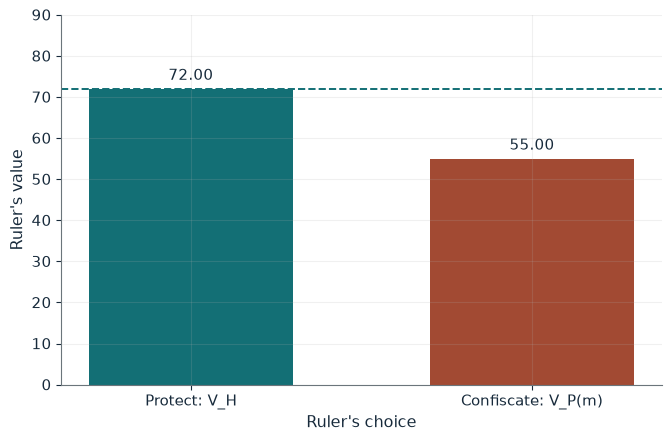

Cooperate value V_H      72.00
Confiscate value V_P(m)  55.00
Threshold share m*       0.764
Share withdrawn m        1.000
Ruler's choice           Protect

Worked steps:
  1. V_H = (24 - 6) / (1 - 0.75) = 18 / 0.25 = 72.00
  2. Commerce kept after confiscation: (1 - 1.000) x 72.00 = 0.00
  3. V_P(m) = 55 + 0.00 = 55.00
  4. m* = 55 / 72.00 = 0.764
  5. V_P(m) = 55.00 against V_H = 72.00: protection pays and the ruler respects property

Constructed teaching numbers, not historical data. Cooperation is worth (24 - 6) / (1 - 0.75) = 72.00. Withdrawing 1.000 of commerce leaves the ruler 55 + 0.00 = 55.00 from confiscation, so protection pays and the ruler respects property. Deterrence needs m at least 55 / 72.00 = 0.764.


In [2]:
show(guild_picture(m=1.0, delta=0.75))

Change one input, `m`, and hold the others at the book's values:

In [3]:
sweep(guild_picture, 'm', [0.25, 0.5, 0.764, 1.0], {'delta': 0.75}, ['Confiscate value V_P(m)', "Ruler's choice"])

m | Confiscate value V_P(m) | Ruler's choice
0.25 | 109.00 | Confiscate
0.5 | 91.00 | Confiscate
0.764 | 71.99 | Protect
1.0 | 55.00 | Protect


A full embargo leaves the ruler 55 against 72, so protection pays. With only a quarter of commerce withdrawn the grab is worth 109 and the threat fails; the boycott must remove at least 0.764.

## 2. Fiscal-military state: taxes that let a state borrow for war

Constructed teaching numbers, not historical data. Debt 240 at 5 percent, civilian spending 60, military spending 90 in war and 35 in peace.

$$D_{t+1}=1.05(240)+60+90-120=282, \qquad D_{t+2}=1.05(282)+60+35-120=271.10$$

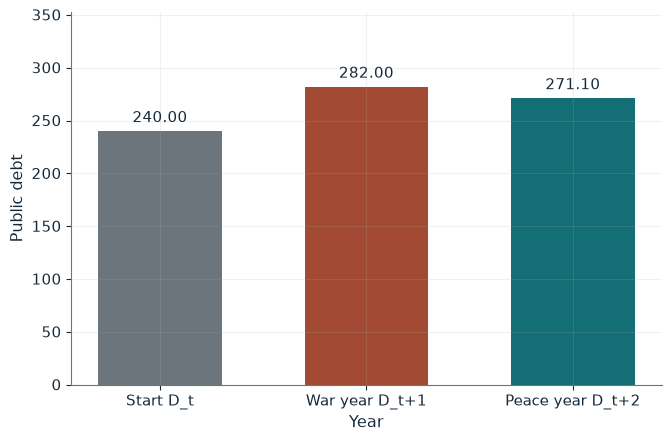

War year debt D_t+1    282.00
War borrowing          42.00
Peace year debt D_t+2  271.10
Peace primary surplus  25.00
Peace interest         14.10
Peace change in debt   -10.90

Worked steps:
  1. D_t+1 = 1.05 x 240 + 60 + 90 - 120 = 252.00 + 150 - 120 = 282.00
  2. War borrowing = 282.00 - 240 = 42.00
  3. D_t+2 = 1.05 x 282.00 + 60 + 35 - 120 = 296.10 + 95 - 120 = 271.10
  4. Primary surplus = 120 - 60 - 35 = 25.00; interest = 0.05 x 282.00 = 14.10
  5. Change in peace = 14.10 - 25.00 = -10.90, so debt falls by 10.90

Constructed teaching numbers, not historical data. With taxes of 120 and interest at 5%, war-year debt is 1.05 x 240 + 60 + 90 - 120 = 282.00, so the state borrows 42.00. In the peace year the primary surplus is 25.00 against interest of 14.10, so debt falls by 10.90.


In [4]:
show(war_debt_picture(tax=120, r=0.05))

Change one input, `tax`, and hold the others at the book's values:

In [5]:
sweep(war_debt_picture, 'tax', [95, 120, 145], {'r': 0.05}, ['War borrowing', 'Peace year debt D_t+2'])

tax | War borrowing | Peace year debt D_t+2
95 | 67.00 | 322.35
120 | 42.00 | 271.10
145 | 17.00 | 219.85


With taxes of 120 the state borrows 42 in war; without the excise (95) it borrows 67. In peace the primary surplus of 25 exceeds interest of 14.10, so debt falls by 10.90.

## 3. Reversal of fortune: rich colonies that fell behind

Constructed teaching numbers, not historical data. Prosperity 0.90 in A and 0.30 in B, incomes 150 and 100.

$$J=1-0.60P, \qquad g=0.008+0.025J$$

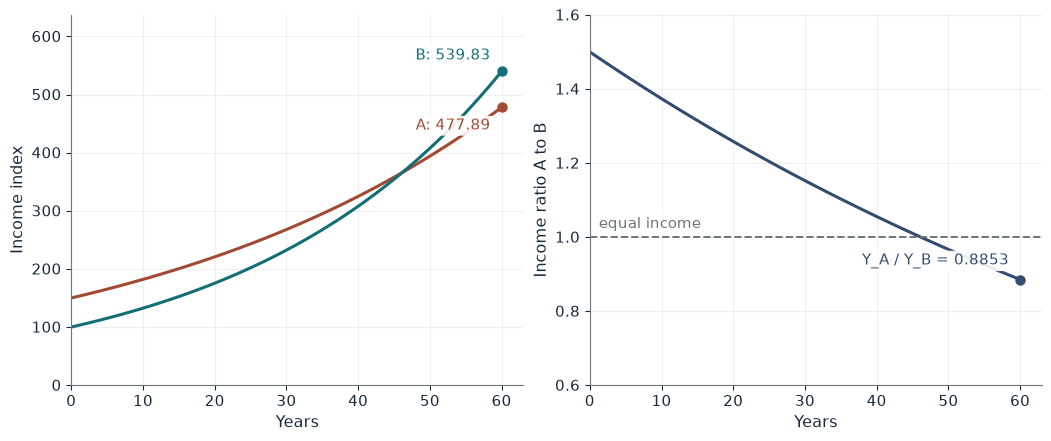

J_A              0.460
J_B              0.820
g_A              1.950%
g_B              2.850%
Y_A              477.89
Y_B              539.83
Ratio Y_A / Y_B  0.8853

Worked steps:
  1. J_A = 1 - 0.60 x 0.90 = 0.460; J_B = 1 - 0.60 x 0.30 = 0.820
  2. g_A = 0.008 + 0.025 x 0.460 = 0.01950; g_B = 0.008 + 0.025 x 0.820 = 0.02850
  3. Y_A = 150 x (1.01950)^60 = 477.89
  4. Y_B = 100 x (1.02850)^60 = 539.83
  5. Y_A / Y_B = 477.89 / 539.83 = 0.8853

Constructed teaching numbers, not historical data. With slope 0.60, inclusion is 0.460 in A and 0.820 in B, so A grows 0.008 + 0.025 x 0.460 = 0.01950 a year and B 0.008 + 0.025 x 0.820 = 0.02850. After 60 years income is 477.89 in A and 539.83 in B: B has overtaken A, which is 11.5% poorer.


In [6]:
show(reversal_picture(beta=0.60, years=60))

Change one input, `years`, and hold the others at the book's values:

In [7]:
sweep(reversal_picture, 'years', [20, 40, 60], {'beta': 0.6}, ['Y_A', 'Y_B', 'Ratio Y_A / Y_B'])

years | Y_A | Y_B | Ratio Y_A / Y_B
20 | 220.72 | 175.42 | 1.2582
40 | 324.77 | 307.73 | 1.0554
60 | 477.89 | 539.83 | 0.8853


A grows 1.95 percent a year and B 2.85 percent. A is still ahead after 40 years, but after 60 the ratio is 0.8853: A is about 11.5 percent poorer.

## 4. Advantage of backwardness: catching up from far behind

Constructed teaching numbers, not historical data. The frontier is 100 and each economy closes a share of its gap.

$$A_1=35+0.25(100-35)=51.25, \qquad PV=20\left(\frac{1-(1.08)^{-5}}{0.08}\right)\approx79.85$$

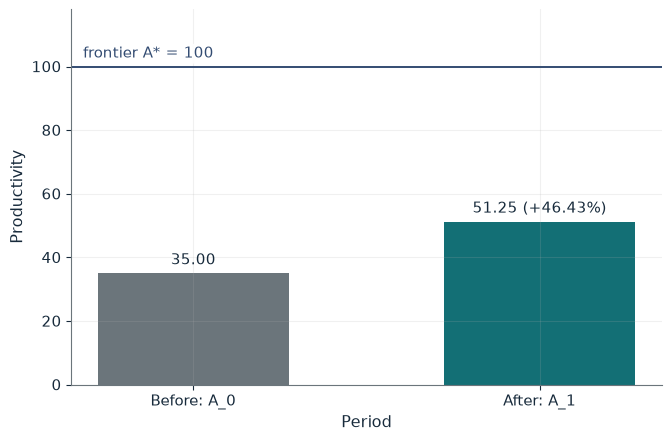

A_1          51.25
Growth       46.43%
Gap closed   16.25
Package PV   79.85
Package NPV  7.85

Worked steps:
  1. Gap = 100 - 35 = 65
  2. A_1 = 35 + 0.25 x 65 = 35 + 16.25 = 51.25
  3. Growth = (51.25 - 35) / 35 = 0.4643, or 46.43%
  4. PV = 20 x (1 - 1.08^-5) / 0.08 = 79.85; NPV = 79.85 - 72 = 7.85

Constructed teaching numbers, not historical data. Starting at 35 with a gap of 65, closing 25% of it lifts productivity to 35 + 0.25 x 65 = 51.25, growth of 46.43%. The larger the starting gap, the faster the percentage growth from the same catch-up share. The book's adoption package, a fixed example, is worth 79.85 against its cost of 72, an NPV of 7.85.


In [8]:
show(backwardness_picture(a0=35, theta=0.25))

Change one input, `a0`, and hold the others at the book's values:

In [9]:
sweep(backwardness_picture, 'a0', [35, 55, 75], {'theta': 0.25}, ['A_1', 'Growth'])

a0 | A_1 | Growth
35 | 51.25 | 46.43%
55 | 66.25 | 20.45%
75 | 81.25 | 8.33%


The same share gives 46.43 percent growth from 35 and only 8.33 percent from 75. The adoption package is worth 79.85 against its cost of 72, an NPV of 7.85.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

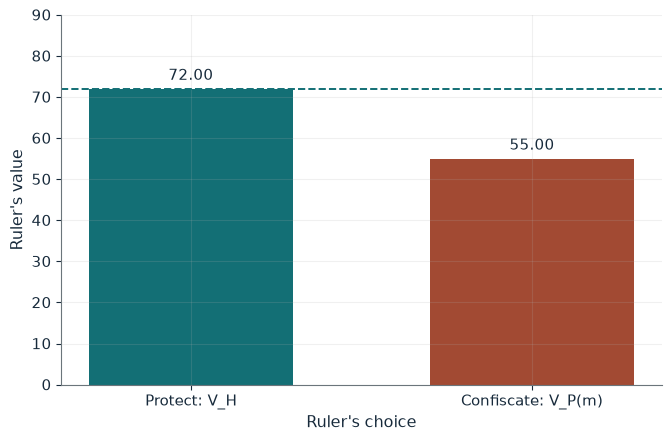

Cooperate value V_H      72.00
Confiscate value V_P(m)  55.00
Threshold share m*       0.764
Share withdrawn m        1.000
Ruler's choice           Protect

Worked steps:
  1. V_H = (24 - 6) / (1 - 0.75) = 18 / 0.25 = 72.00
  2. Commerce kept after confiscation: (1 - 1.000) x 72.00 = 0.00
  3. V_P(m) = 55 + 0.00 = 55.00
  4. m* = 55 / 72.00 = 0.764
  5. V_P(m) = 55.00 against V_H = 72.00: protection pays and the ruler respects property

Constructed teaching numbers, not historical data. Cooperation is worth (24 - 6) / (1 - 0.75) = 72.00. Withdrawing 1.000 of commerce leaves the ruler 55 + 0.00 = 55.00 from confiscation, so protection pays and the ruler respects property. Deterrence needs m at least 55 / 72.00 = 0.764.


In [10]:
show(guild_picture(m=1.0, delta=0.75))

## Practice

**1.** With delta = 0.90 and a full embargo, what is the threshold share m*?

<details><summary>Answer</summary>

V_H = 18 / 0.10 = 180, so m* = 55 / 180 = 0.306.

</details>

**2.** With taxes 145 and r = 0.05, what is war-year debt?

<details><summary>Answer</summary>

1.05 x 240 + 60 + 90 - 145 = 252 + 150 - 145 = 257.

</details>

**3.** With starting productivity 55 and share 0.40, what is A_1 and growth?

<details><summary>Answer</summary>

A_1 = 55 + 0.40 x 45 = 73, so growth is 73 / 55 - 1 = 32.73 percent.

</details>